# Tidal cycles in delay embeddings

A tide gauge records the water level at a harbor. In Boston, the level rises
and falls twice a day, driven mainly by the Moon, with a period of about
12.42 hours. The height of these tides also changes over about two weeks:
spring tides, near new and full moon, rise higher and fall lower than neap
tides, near the quarter moons. Spring tides are also larger when the Moon
is close to the Earth.

This notebook turns a tide gauge record into points with a delay embedding and
summarizes the shape of those points with persistent homology and stable
ranks. Embedding the whole record shows that the water level is periodic.
Cutting the embedding into windows of about one day shows how the tides change
over the spring–neap cycle.

In [1]:
import datetime
from urllib.request import urlopen

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.units as munits
import numpy as np

import stablebear as sb
from stablebear.persistence import (
    barcode_to_stable_rank,
    compute_persistent_homology,
)
from stablebear.plotting import plot, plot_timeseries
from stablebear.timeseries import TimeDelayEmbedding, Times, TimeSeries, Window

# Short date labels without a year offset; the axis labels give the year.
converter = mdates.ConciseDateConverter(show_offset=False)
munits.registry[np.datetime64] = converter
munits.registry[datetime.datetime] = converter

## Loading the water levels

The data are hourly water levels at NOAA station 8443970, Boston, from January
through March 2023. NOAA's Center for Operational Oceanographic Products and
Services (CO-OPS) publishes them through its
[data API](https://api.tidesandcurrents.noaa.gov/api/prod/). As a work of the
US federal government, the data are in the public domain. Levels are in
meters relative to mean sea level, and timestamps are in GMT.

In [2]:
url = (
    "https://api.tidesandcurrents.noaa.gov/api/prod/datagetter"
    "?product=hourly_height&station=8443970"
    "&begin_date=20230101&end_date=20230331"
    "&datum=MSL&units=metric&time_zone=gmt&format=csv"
    "&application=stablebear_tutorial"
)
with urlopen(url) as response:
    rows = [line.split(",") for line in
            response.read().decode().splitlines()[1:]]

stamps = np.array([row[0] for row in rows], dtype="datetime64[m]")
levels = np.array([float(row[1]) for row in rows])
print(f"{len(levels)} hourly levels from {stamps[0]} to {stamps[-1]}")

2160 hourly levels from 2023-01-01T00:00 to 2023-03-31T23:00


A time series holds the levels with their timestamps. Building its times from
the dates counts them in minutes from the first one, the resolution of the
NOAA timestamps, and keeps that first date as the epoch, so the series can be
drawn and queried at dates. Reading the series in hours with `to("h")` keeps
the timestamps and makes the delays and window sizes below hours as well.

In [3]:
series = TimeSeries(levels, times=Times(stamps, unit="min")).to("h")

The figure shows the whole record and, cut out as a window of three days, its
first three days.

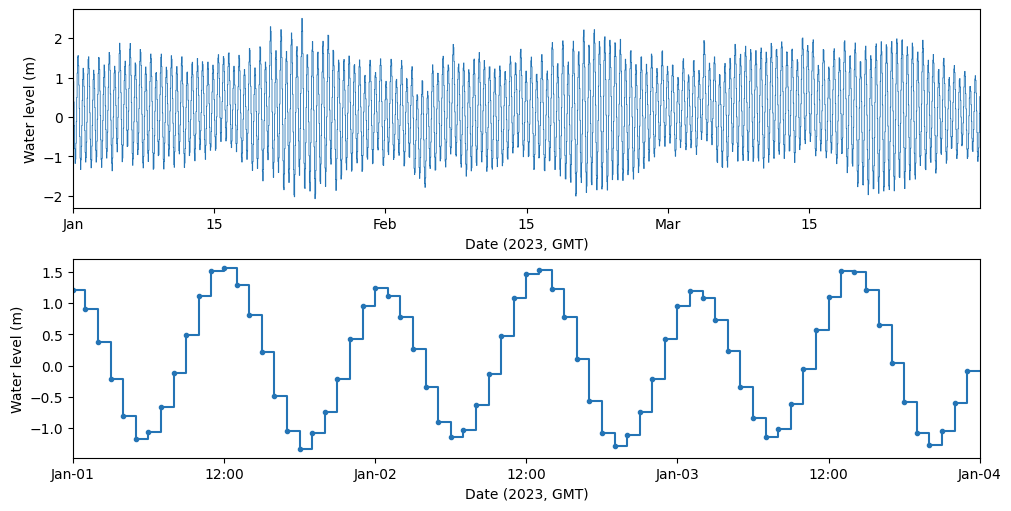

In [4]:
fig, (ax_all, ax_zoom) = plt.subplots(
    2, 1, figsize=(10, 5), layout="constrained",
)
plot_timeseries(series, ax=ax_all, color="#2474b5", linewidth=0.6)
ax_all.set(xlabel="Date (2023, GMT)", ylabel="Water level (m)",
           xlim=(stamps[0], stamps[-1]))
first_days = Window(size=np.timedelta64(3, "D"), anchor="start")(series)[0]
plot_timeseries(first_days, ax=ax_zoom, color="#2474b5", markers=True,
                markersize=3)
ax_zoom.set(xlabel="Date (2023, GMT)", ylabel="Water level (m)",
            xlim=first_days.bounds(dates=True)[:2])
plt.show()

The first three days show two high and two low tides per day, with
consecutive high tides of different heights. Over the whole record, the range
between high and low tide grows and shrinks: the wide stretches are spring
tides and the narrow ones neap tides.

## Embedding the whole record

A delay embedding of dimension 2 and delay $\delta$ maps the level $x(t)$ at
time $t$ to the point $\bigl(x(t - \delta), x(t)\bigr)$. For a sine with period
$P$, a delay of $P / 4$ traces a circle. We use a delay of 3 hours, close to a
quarter of 12.42 hours, so each tidal cycle traces a loop around the origin.

In [5]:
embedded = TimeDelayEmbedding(dimension=2, delay=3.0)(series)
points = np.asarray(embedded.values)
print("Embedded points:", points.shape)

Embedded points: (2157, 2)


We color each point by its time.

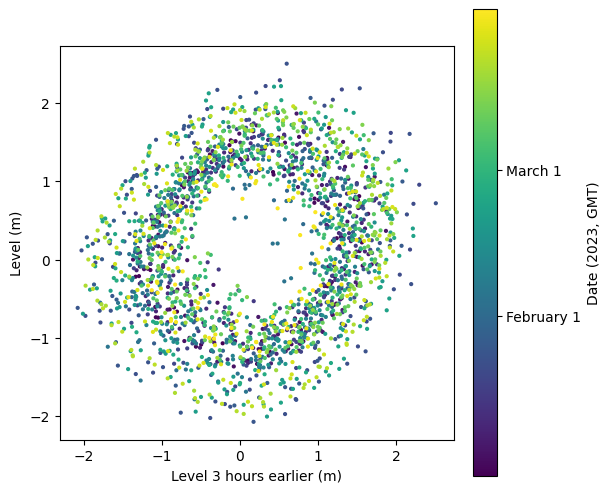

In [6]:
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
colored = ax.scatter(
    *points.T, c=mdates.date2num(embedded.times.to_datetime64()), cmap="viridis",
    s=4,
)
ax.set(xlabel="Level 3 hours earlier (m)", ylabel="Level (m)",
       aspect="equal")
fig.colorbar(colored, ax=ax, label="Date (2023, GMT)",
             ticks=mdates.MonthLocator(),
             format=mdates.DateFormatter("%B %-d"))
plt.show()

The points form an annulus, and each tidal cycle goes once around it. The
hole in the middle comes from the periodic tide: when the level crosses its
mean, the level 3 hours earlier is near a high or low tide, so no point lies
near the origin. Points from all weeks are spread over the whole annulus, so
the embedding does not show when large or small tides occurred.

## Persistence of the whole embedding

We compute the persistent homology of the embedded points with the
Vietoris–Rips complex and summarize each barcode with its stable rank. At a
threshold $t$, the stable rank counts the bars with lifetimes longer than $t$.
`reduced=True` removes the infinite $H_0$ bar, so both curves have finite
norms.

In [7]:
barcodes = compute_persistent_homology(
    embedded.values, max_dim=1, reduced=True,
)
ranks = barcode_to_stable_rank(barcodes)

h1 = np.asarray(barcodes[1])
lifetimes = np.sort(h1[:, 1] - h1[:, 0])[::-1]
print(f"{len(lifetimes)} H1 bars; the longest lifetimes (m):",
      np.round(lifetimes[:4], 3))

571 H1 bars; the longest lifetimes (m): [0.671 0.16  0.159 0.133]


The $H_1$ stable rank shows how quickly these bars die out.

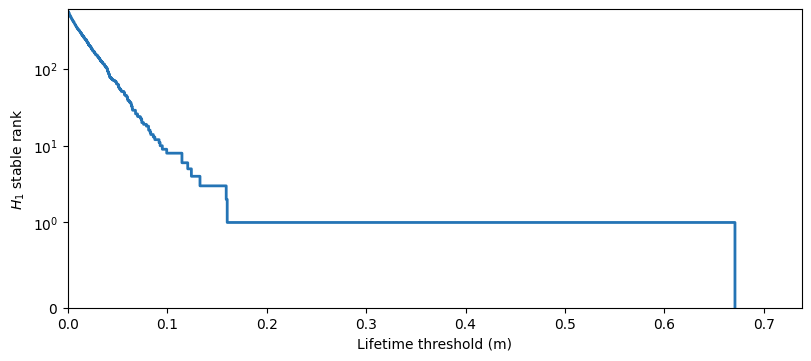

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
plot(ranks[1], ax=ax, color="#2474b5", linewidth=2)
ax.set(xlabel="Lifetime threshold (m)", ylabel="$H_1$ stable rank",
       xlim=(0, 1.1 * lifetimes[0]))
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(bottom=0)
plt.show()

The vertical axis is linear up to 1 and logarithmic above. Hundreds of loops
have lifetimes of a few centimeters. They come from gaps between neighboring
cycles in the annulus and from the hourly sampling, and all of them live
shorter than 0.17 m. One loop lives about four times as long as any other:
the hole of the annulus.

The whole embedding answers the first question: the water level is periodic.
It does not show when the tides were large. Cycles from spring and neap tides
lie on top of each other, and the stable rank of the whole record cannot tell
which cycle came from which week.

## Embedding windows of about one day

To follow the tides over time, we cut the embedding into windows with
`Window` and compute one stable rank per window. A window of 25 hours covers
two tidal cycles of 12.42 hours. A new window starts every 3 hours, so
neighboring windows overlap.

In [9]:
windows = Window(size=25.0, step=3.0, anchor="start")(embedded)
window_dates = np.array([windows[k].bounds(dates=True).start
                         for k in range(windows.shape[0])])
print("Windows:", windows.shape)

Windows: Shape(711)


Each window is a time series of its own, with time starting at 0. Evaluating
all windows at the whole hours 0 to 24 gives a tensor of shape
`(n_windows, 25, 2)`, whose last two axes are a point cloud of 25 points for
each window. The persistent homology of this tensor gives one barcode per window
and homology dimension.

In [10]:
window_points = windows(np.arange(25.0))
window_barcodes = compute_persistent_homology(
    window_points, max_dim=1, reduced=True,
)
window_ranks = barcode_to_stable_rank(window_barcodes)
print("Window points:", window_points.shape)
print("Window stable ranks (window, homology):", window_ranks.shape)

Window points: Shape(711, 25, 2)
Window stable ranks (window, homology): Shape(711, 2)


To compare spring and neap tides, we pick the windows with the largest and
the smallest tidal range, the difference between their highest and lowest
levels.

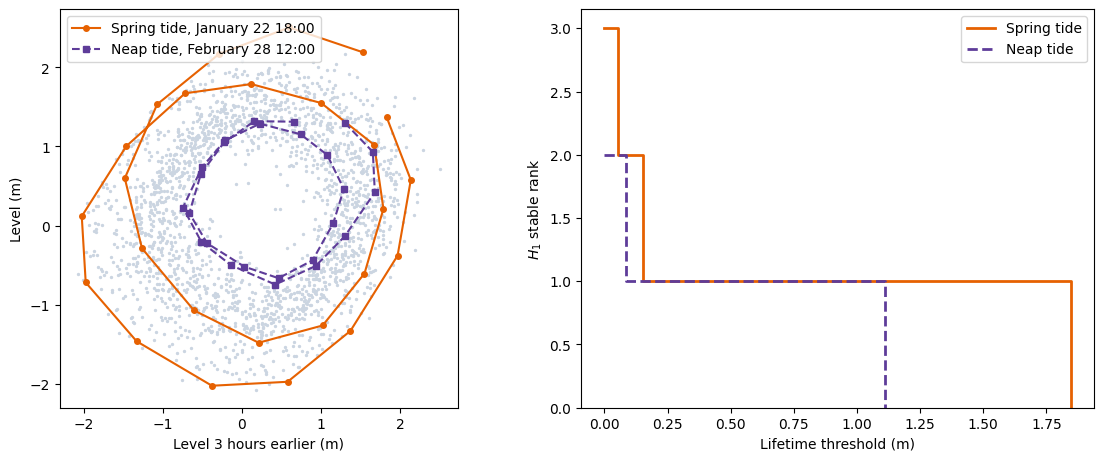

In [11]:
window_array = np.asarray(window_points)
tidal_range = np.ptp(window_array[:, :, 1], axis=1)
spring, neap = np.argmax(tidal_range), np.argmin(tidal_range)

examples = [(spring, "Spring tide", "#e66101", "-", "o"),
            (neap, "Neap tide", "#5e3c99", "--", "s")]
fig, (ax_points, ax_ranks) = plt.subplots(
    1, 2, figsize=(11, 4.5), layout="constrained",
)
ax_points.scatter(*points.T, s=2, color="#cbd5e1")
for i, label, color, style, marker in examples:
    start = window_dates[i].astype(object)
    ax_points.plot(*window_array[i].T, color=color, linestyle=style,
                   marker=marker, markersize=4,
                   label=f"{label}, {start:%B %-d %H:%M}")
    plot(window_ranks[i, 1], ax=ax_ranks, color=color, fmt=style,
         linewidth=2, label=label)
ax_points.set(xlabel="Level 3 hours earlier (m)", ylabel="Level (m)",
              aspect="equal")
ax_points.legend(loc="upper left")
ax_ranks.set(xlabel="Lifetime threshold (m)", ylabel="$H_1$ stable rank")
ax_ranks.set_ylim(bottom=0)
ax_ranks.legend()
plt.show()

On the left, gray points are the whole embedding, and the lines join the 25
points of each window in time order. Each window goes twice around the origin.
The spring-tide window traces large loops near the outer edge of the annulus,
and the neap-tide window small loops near the hole.

On the right, each stable rank has one long-lived loop. The two cycles of a
window go around the same hole, so they give one long bar between them, and
the gaps between the cycles give a few short bars. The long bar of the
spring-tide window lives longer because its cycles enclose a larger hole.

## Following the loops over time

The $L_1$ norm of the $H_1$ stable rank of a window,

$$\lVert r_1 \rVert_1 = \int_0^\infty r_1(t)\,dt,$$

is the sum of the lifetimes of its loops. It grows with the size of the
loops the tides trace. We compare it with the tidal range of each window.

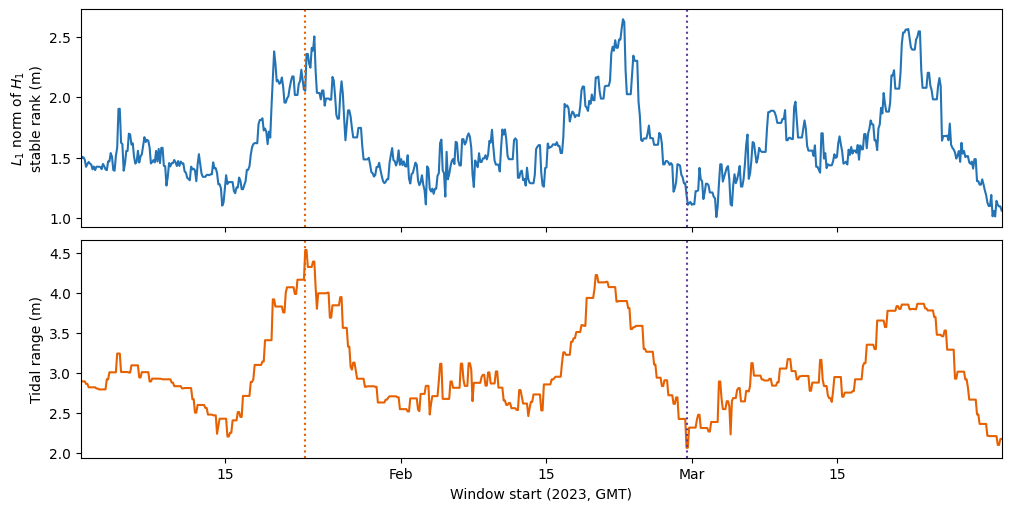

Correlation between norm and tidal range: 0.89


In [12]:
h1_norms = np.asarray(sb.lp_norm(window_ranks[:, 1], p=1))

fig, (ax_norm, ax_range) = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True, layout="constrained",
)
ax_norm.plot(window_dates, h1_norms, color="#2474b5")
ax_norm.set(ylabel="$L_1$ norm of $H_1$\nstable rank (m)")
ax_range.plot(window_dates, tidal_range, color="#e66101")
ax_range.set(xlabel="Window start (2023, GMT)", ylabel="Tidal range (m)",
             xlim=(window_dates[0], window_dates[-1]))
for ax in (ax_norm, ax_range):
    for i, _, color, _, marker in examples:
        ax.axvline(window_dates[i], color=color, linestyle=":")
plt.show()

print("Correlation between norm and tidal range:",
      round(np.corrcoef(h1_norms, tidal_range)[0, 1], 2))

Dotted lines mark the spring-tide and neap-tide windows from the previous
figure. The norm rises and falls with the tidal range. Both curves have large
peaks near the new moons of January 21, February 20, and March 21, and
smaller peaks near the full moons in between. In January and February, the
new moon fell within a day of the Moon's closest approach to the Earth. The
curves do not match exactly: the norm measures the
loops traced by a whole window, while the tidal range compares only its
highest and lowest levels.

## Comparing all windows

The norm reduces each stable rank to one number. The $L_1$ distance between
the stable ranks of two windows compares the curves themselves, and `pdist`
computes it for every pair of windows.

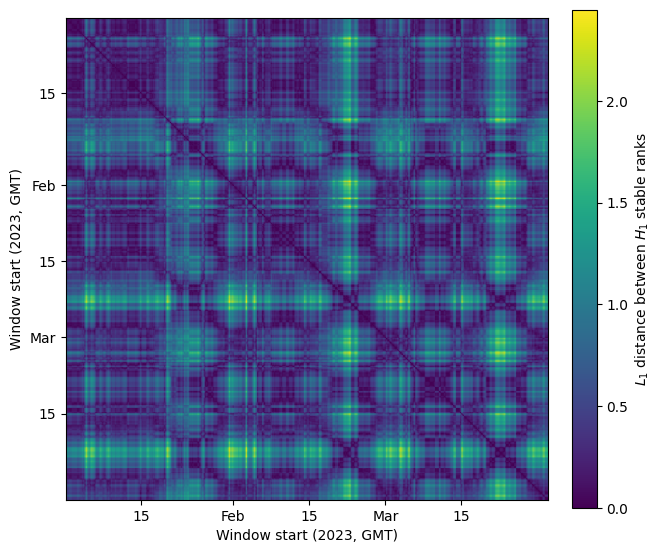

In [13]:
distances = sb.pdist(window_ranks[:, 1], p=1).to_dense()

fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
first_window, last_window = mdates.date2num(window_dates[[0, -1]])
image = ax.imshow(
    distances, cmap="viridis",
    extent=(first_window, last_window, last_window, first_window),
)
ax.xaxis_date()
ax.yaxis_date()
ax.set(xlabel="Window start (2023, GMT)",
       ylabel="Window start (2023, GMT)")
fig.colorbar(image, ax=ax, label="$L_1$ distance between $H_1$ stable ranks")
plt.show()

Dark regions group windows with similar stable ranks. The bright bands at
the large spring tides, in late January, February, and March, show that
their stable ranks differ from those of all other windows. Where the bands
cross, the
large spring tides are close to each other again, so the pattern repeats
about every 29 days. This time structure comes from the shape of the windows
alone.

## Summary

The delay embedding of the whole record is an annulus. Its one long-lived
$H_1$ bar shows that the water level is periodic. Windows of one day trace
loops whose size follows the tides, so the stable ranks of the windows track
the spring–neap cycle that the whole record mixes together, including the
larger monthly variation of the spring tides. The same steps
apply to other periodic records: choose a delay near a quarter of the period
and a window that covers a few periods.